<h1 style="border-bottom: 3px solid #000080; padding-bottom: 5px; font-weight: bold;">1. はじめに</h1>

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">スタートとゴール</h2>


* **文書の長さ・単語の出現回数などの話題からスタート**します。

* **試しに実行しながらLLMを楽しめる状態になるまでをゴール**とします。

* サンプルコードを上から実行して結果を見つつ、演習に関しては手を動かすという構成です。

* 題材として[Natural Language Processing with Disaster Tweets](https://www.kaggle.com/competitions/nlp-getting-started)というコンペティション(以下、Disasterコンペ)を扱います。

* テーブルデータの課題に入門したことがあるような人が読むのを想定しています。

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">目次</h2>

このNotebookの目次は以下の通りです。

まずはテキストをもとに単語の出現回数や出現頻度に関する特徴量を作成する方法を扱います。

その後に、事前学習済み言語モデルを利用してテキストを元に予測をします。

1. はじめに

2. 課題の確認

3. 文書の長さ・単語の出現回数・n-gram

4. 事前学習済み言語モデル - BERT関連

5. 事前学習済み言語モデル - Gemma, Qwen, gpt-ossなど

6. 自然言語処理 - 様々なコンペティション


<h2 style="border-left: 5px solid #000080; padding-left: 10px;">注意事項</h2>

* 自然言語処理には数多くのトピック（形態素解析、構文解析、文法チェック、スペルチェック、感情分析、固有表現抽出、word2vec、文埋め込み、要約生成、BM25、・・・）がありますが、このNotebookはすべてを網羅するようなものではありません。

* **Dark Themeを設定している方は一部の表示が崩れる場合があります**ので、Light Themeに変更していただけると幸いです。（View>Theme settingsから変更できます。）

* 演習の解答は1つに定まらないですが、参考として解答例をつけています。また、通常のコーディングに比べてかなり細かくコメントをつけています。

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">おすすめの書籍</h2>

自然言語処理に関しては色々な書籍がありますが、学部の教養課程で学ぶような微積・線形代数を知っている方で大規模言語モデルへ入門されたい方には以下の2冊が個人的にはおすすめです。

- [山田育矢，鈴木正敏，山田康輔，李凌寒（2023）『大規模言語モデル入門』技術評論社．](https://gihyo.jp/book/2023/978-4-297-13633-8)

- [山田育矢，鈴木正敏，西川荘介，藤井一喜，山田康輔，李凌寒（2024）『大規模言語モデル入門Ⅱ〜生成型LLMの実装と評価』技術評論社．](https://gihyo.jp/book/2024/978-4-297-14393-0)

<h1 style="border-bottom: 3px solid #000080; padding-bottom: 5px; font-weight: bold;">2. 課題の確認</h1>

<div style="background-color: #e6f7ff; color: #00509e; padding: 16px; margin: 24px; border-radius: 5px;">
  <strong style="font-size: 1.2em;">ポイント</strong>

  <ul style="color: #000000; font-size: 1em; margin-top: 10px; list-style-type: none; padding-left: 0;">
    <li style="margin-bottom: 5px;"><span style="color: #00509e;">&#8226;</span> 問題に取り組む前に、課題の概要・評価指標・与えられるデータを丁寧に把握する必要がある。</li>
    <li><span style="color: #00509e;">&#8226;</span> OverviewやDataは英語で書かれているので、必要であれば日本語に翻訳して理解する。</li>
  </ul>
</div>


<h2 style="border-left: 5px solid #000080; padding-left: 10px;">課題の概要</h2>

 -  DisasterコンペはTwitterでのツイートが実際の災害や事件に関するものかどうかを予測する課題が与えられます。

 - **ツイートが緊急事態なのかどうかを正確に検知したい**というモチベーションがあります。

 - **比喩的な表現やデマ**などによって正確に検知しにくいという課題があります。 

 - データセットは扱いやすいサイズ（1.43MB）であり、**自然言語処理に入門したい方にとって取り組みやすい課題**となっています。

 - コードを提出する形式ではなく、予測したデータをcsvファイルで提出する形式です。

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">評価指標</h2>

 実際の災害に関するツイートかどうかを0か1に分類するタスクで、**F1スコア**で評価されます。

 F1スコアは**適合率（precision)** と **再現率(recall)** の調和平均で、以下の式で定義されます。

 $$
 F_1 = 2 * \frac{\text{precision}*\text{recall}}{\text{precision}+\text{recall}}
 $$

 F1スコアはprecisionとrecallのバランスを取った評価指標です。

- precision: `1`と予測したものの中で、実際に`1`であったものの割合。

  - 「災害ツイートでないのに災害と判定するような誤検知(FP)」を無くすほど1に近づきます。
 
  - $\displaystyle\text{precision} = \frac{\text{TP}}{\text{TP}+\text{FP}}
 $


- recall: 実際に`1`であったものの中で、`1`と予測されたものの割合。

  - 「災害ツイートを見逃してしまうケース(FN)」を無くすほど1に近づきます。
 
  - $\displaystyle\text{recall} = \frac{\text{TP}}{\text{TP}+\text{FN}}$
 
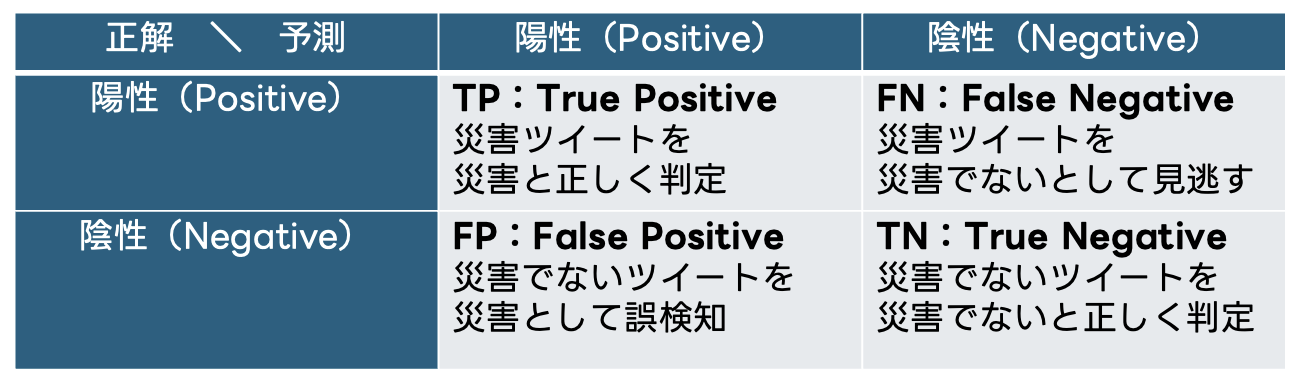

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">与えられるデータ</h2>

 与えられているファイルは以下の3つでとてもシンプルです。

 - `train.csv` - 学習データのファイル。

 - `test.csv` - テストデータのファイル。

 - `sample_submission.csv` - 提出の形式を例示するためのサンプル。

学習データ・テストデータには以下の列が存在します。

- `id` - 各ツイートに対応するID（一意の識別子）

- `text` - ツイートされたテキスト

- `location` - ツイートされた場所（空の場合もある）

- `keyword` - ツイートの特定のキーワード（空の場合もある）

- `target` - train.csvにだけあり、ツイートが実際の災害に関するものである場合に`1`で、そうでない場合に`0`

各ファイルの先頭部分に保存されているデータは以下のようになっています。
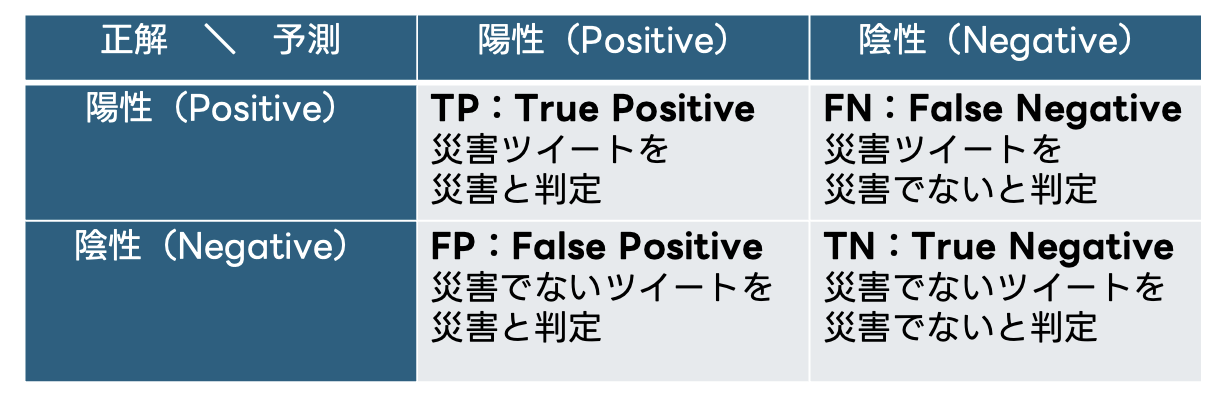
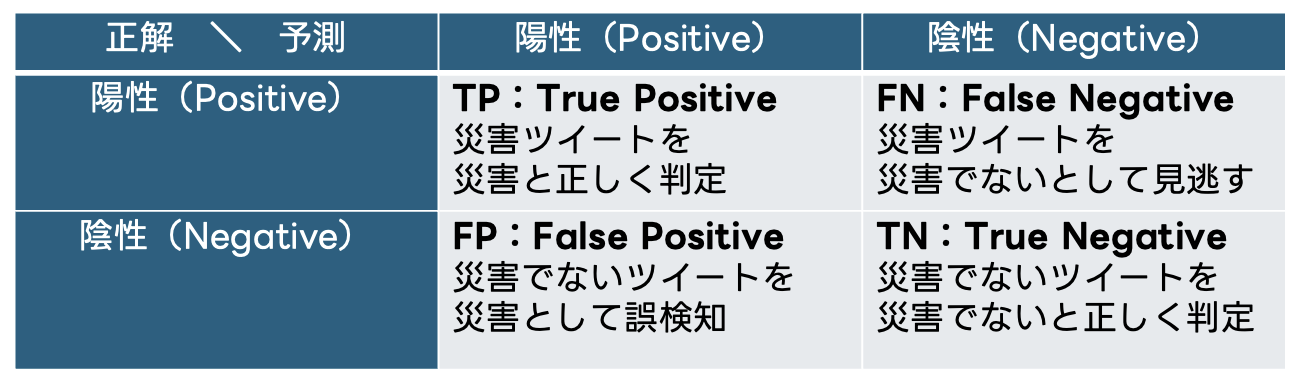

In [ ]:
# サンプルコード：　2-1

import pandas as pd

train_df = pd.read_csv('/kaggle/input/nlp-getting-started/train.csv')
test_df = pd.read_csv('/kaggle/input/nlp-getting-started/test.csv')
sample_df = pd.read_csv('/kaggle/input/nlp-getting-started/sample_submission.csv')

# ヘッダーを装飾する関数
def print_section_header(title):
    print(f'\n{"="*10} {title} {"="*10}\n')

# データの先頭を表示する関数
def display_data_head(df, df_name):
    print_section_header(f'{df_name}の先頭部分')
    # データフレームの先頭5行を表示
    display(df.head())  # KaggleのNotebookではdisplay関数がデータフレームの見やすい表示に役立ちます

pd.set_option('display.max_colwidth', None)   # 列幅制限なし
pd.set_option('display.max_columns', None)   # 全カラム表示
pd.set_option('display.width', 0)            # 自動折り返しを防止


# 学習用のデータ
display_data_head(train_df, '学習データ')

# テスト用のデータ
display_data_head(test_df, 'テストデータ')

# サンプル提出データ
display_data_head(sample_df, 'サンプル提出データ')

# <h1 style="border-bottom: 3px solid #000080; padding-bottom: 5px; font-weight: bold;">3. 文書の長さ・単語の出現回数・n-gram</h1>

<div style="background-color: #e6f7ff; color: #00509e; padding: 16px; margin: 24px; border-radius: 5px;">
  <strong style="font-size: 1.2em;">ポイント</strong>

  <ul style="color: #000000; font-size: 1em; margin-top: 10px; list-style-type: none; padding-left: 0;">
    <li style="margin-bottom: 5px;"><span style="color: #00509e;">&#8226;</span> テキストデータを扱いたい際に、複雑な手法を用いる前に文書の長さや単語の出現回数を確認することも重要。</li>
    <li><span style="color: #00509e;">&#8226;</span> 序盤に基本的な特徴を確認しておくと分析しやすくなる。</li>
  </ul>
</div>

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">文書の長さ</h2>

実際の災害かどうかを判定するために複雑なモデルを使いたくなりますが、まずはどれくらいの長さの文書なのかを把握しましょう。

文字列に対して、文字数は`len()`を使うと確認できます。

単語数は英語であればスペースで単語が区切られているので、`.split()`で分割した後に何個に区切られるかを計算するとよいです。（誤字脱字などの細かい点を考慮した計算ではないですが）

単語数や文字列を可視化するサンプルコードは3-1に記載してあります。

pandasでは以下のように.str（strアクセサ）を利用することで各行の文字列に対して一括して処理を適用できます。

（他にどのような処理をできるか気になった方は[pandasのドキュメント](https://pandas.pydata.org/docs/user_guide/text.html)をチェックしてみてください）

In [ ]:
# サンプルコード：　3-1

import matplotlib.pyplot as plt
import pandas as pd

for df in (train_df, test_df):
    df['text'] = df['text'].fillna('').astype(str)
    # 文字数
    df['text_length'] = df['text'].str.len()
    # 単語数
    df['word_count'] = df['text'].str.split().str.len()

# ヒストグラムのbinの範囲
min_length = min(train_df['text_length'].min(), test_df['text_length'].min())
max_length = max(train_df['text_length'].max(), test_df['text_length'].max())
bins_length = 15

min_words = min(train_df['word_count'].min(), test_df['word_count'].min())
max_words = max(train_df['word_count'].max(), test_df['word_count'].max())
bins_words = 15

plt.figure(figsize=(10, 6))

# 文字数の分布（train：targetごと）
plt.subplot(2, 2, 1)
plt.hist(train_df[train_df['target'] == 0]['text_length'],
         bins=bins_length, range=(min_length, max_length),
         alpha=0.5, label='Not Disaster', color='blue', edgecolor='black')
plt.hist(train_df[train_df['target'] == 1]['text_length'],
         bins=bins_length, range=(min_length, max_length),
         alpha=0.5, label='Disaster', color='orange', edgecolor='black')
plt.title('Text Length Distribution by Target (Character Count)')
plt.xlabel('Number of Characters'); plt.ylabel('Frequency'); plt.legend()

# 単語数の分布（train：targetごと）
plt.subplot(2, 2, 2)
plt.hist(train_df[train_df['target'] == 0]['word_count'],
         bins=bins_words, range=(min_words, max_words),
         alpha=0.5, label='Not Disaster', color='blue', edgecolor='black')
plt.hist(train_df[train_df['target'] == 1]['word_count'],
         bins=bins_words, range=(min_words, max_words),
         alpha=0.5, label='Disaster', color='orange', edgecolor='black')
plt.title('Word Count Distribution by Target')
plt.xlabel('Number of Words'); plt.ylabel('Frequency'); plt.legend()

# testの文字数分布
plt.subplot(2, 2, 3)
plt.hist(test_df['text_length'], bins=bins_length,
         range=(min_length, max_length), color='green', edgecolor='black')
plt.title('Text Length Distribution in Test Data (Character Count)')
plt.xlabel('Number of Characters'); plt.ylabel('Frequency')

# testの単語数分布
plt.subplot(2, 2, 4)
plt.hist(test_df['word_count'], bins=bins_words,
         range=(min_words, max_words), color='green', edgecolor='black')
plt.title('Word Count Distribution in Test Data')
plt.xlabel('Number of Words'); plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


文字数の分布・単語数の分布をグラフで確認すると、ツイートなのでほとんどの文字数が140字以下であることが読み取れます。

学習データとテストデータの違いはあまりない様子です。

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">単語の出現回数</h2>

災害や事件に関する単語がどれくらい含まれているかをチェックするという方針が最初に思い浮かぶかもしれません。

単語の順番などを考慮せずに各単語の出現回数を数えるシンプルな手法を試してみましょう。

どの単語が何回登場したかを数えたいわけですが、[scikit-learnのCountVectorizer](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)を使うと簡単に数えられます。

小さなサンプルデータに対するCountVectorizerの使用例は以下の通りです。

In [ ]:
# サンプルコード：　３−2

from sklearn.feature_extraction.text import CountVectorizer

# pandasのサンプルデータを作成
sample_data = {
    'text': [
        "I love machine learning. I love coding.",
        "Machine learning is amazing",
        "I love Kaggle",
        "Kaggle is great for machine learning"
    ]
}
sample_df = pd.DataFrame(sample_data)

# CountVectorizerのインスタンスを作成
sample_vectorizer = CountVectorizer()

# テキストデータを元に出現回数をカウント
vectorized_text = sample_vectorizer.fit_transform(sample_df['text'])

# 特徴量をDataFrameに変換
sample_features = pd.DataFrame(vectorized_text.toarray(), columns=sample_vectorizer.get_feature_names_out())

# 元のDataFrameに特徴量を結合
sample_df_with_features = pd.concat([sample_df, sample_features], axis=1)

# 結果を表示
print("\n特徴量を追加したサンプルデータ:")
display(sample_df_with_features)

それぞれの行を見ると、各単語の出現回数が並んでいますね！

以下のように、wordcloudライブラリを利用すると出現する回数の多い単語を可視化できます。

In [ ]:
# サンプルコード：　３−3
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def generate_wordcloud(texts, title, colormap="viridis"):
    text_all = " ".join(texts)
    wc = WordCloud(width=800, height=400,
                   background_color="white",
                   colormap=colormap,
                   max_words=200).generate(text_all)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=16)
    plt.show()

# 災害ツイート (target==1)
generate_wordcloud(train_df[train_df["target"] == 1]["text"], "Word Cloud: Disaster Tweets", colormap="Reds")

# 非災害ツイート (target==0)
generate_wordcloud(train_df[train_df["target"] == 0]["text"], "Word Cloud: Not Disaster Tweets", colormap="Blues")

# テストデータ全体
generate_wordcloud(test_df["text"], "Word Cloud: Test Data", colormap="Greens")


<h2 style="border-left: 5px solid #000080; padding-left: 10px;">n-gram</h2>

単語の出現回数を数えるときに、「連続する2つの単語の組み合わせについても出現回数を数えたい」と思うときがあるかもしれません。

例えば、単に`fire`という単語の出現回数を数えるだけでは、それが「経済的自立と早期退職」を表して使われていても気づけないかもしれません。`forest fire`という2単語の組み合わせで数えれば山火事を意味しているとわかります。

テキスト内の連続するn個の単語（あるいは文字）の組み合わせを**n-gram**と言います。

特に、n=1の場合はuni-gram、n=2の場合はbi-gram、n=3の場合はtri-gramと呼びます。


`CountVectorizer`の`ngram_range`というパラメータを使うと、以下のように計算することができます。

In [ ]:
# サンプルコード：　3-4

from sklearn.feature_extraction.text import CountVectorizer

# pandasのサンプルデータを作成
sample_data = {
    'text': [
        "I love machine learning. I love coding.",
        "Machine learning is amazing",
        "I love Kaggle",
        "Kaggle is great for machine learning"
    ]
}
sample_df = pd.DataFrame(sample_data)

# CountVectorizerのインスタンスを作成 
# ngram_rangeの範囲を調整することで何個の連続する単語の組み合わせを扱うかを決めることができる
# 例えばngram_range=(1,2)と指定すると、uni-gramとbi-gramの両方が数えられる
# r'(?u)\b\w+\b'は1文字の単語も含めたい場合の正規表現
sample_vectorizer = CountVectorizer(ngram_range=(2, 2), token_pattern=r'(?u)\b\w+\b')

# テキストデータをベクトル化
vectorized_text = sample_vectorizer.fit_transform(sample_df['text'])

# 特徴量名とベクトルの対応を表示
sample_features = pd.DataFrame(vectorized_text.toarray(), columns=sample_vectorizer.get_feature_names_out())

# 元のDataFrameに特徴量を結合
sample_df_with_features = pd.concat([sample_df, sample_features], axis=1)

# 結果を表示
print("\n特徴量を追加したサンプルデータ:")
display(sample_df_with_features)

ここまでに出てきた出現回数や出現頻度を特徴量としてLightGBMなどを利用して予測をすることはできますが、それでは文脈などを適切に考慮できていない場合があります。

大量のテキストデータに基づいて事前学習されたモデルを利用することで、より文脈を踏まえた予測をしてみましょう。

<h1 style="border-bottom: 3px solid #000080; padding-bottom: 5px; font-weight: bold;">4．事前学習済み言語モデル - BERT関連</h1>

<div style="background-color: #e6f7ff; color: #00509e; padding: 16px; margin: 24px; border-radius: 5px;">
  <strong style="font-size: 1.2em;">ポイント</strong>

  <ul style="color: #000000; font-size: 1em; margin-top: 10px; list-style-type: none; padding-left: 0;">
    <li style="margin-bottom: 5px;"><span style="color: #00509e;">&#8226;</span> 事前学習とファインチューニングを組み合わせた方法を使うことが標準的。</li>
    <li><span style="color: #00509e;">&#8226;</span> 多くの事前学習済みモデルがHugging Face Hubで公開されている。</li>
  </ul>
</div>

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">事前学習とファインチューニング</h2>

単語の出現回数やTF-IDFなどを扱いましたが、これらを使って予測をする方法では文脈を適切に考慮しにくいです。

このような問題に対応するためには、文脈を考慮したモデルを使います。事前学習とファインチューニングの2段階にわけて学習する方針が標準的です。

- **事前学習（Pre-training）** - 特定のタスクを解く前に、大量のデータを使用してモデルをあらかじめ訓練すること。

- **ファインチューニング（Fine-tuning）** - 事前学習済みモデルを特定のタスクに適応させるために微調整すること。

**BERT**は事前学習とファインチューニングをあわせた代表的な自然言語処理モデルです。（最近のコンペではQwen3やGemma3などの新しいモデルを利用したsolutionが上位の解法となる場合が増えてきていますが、そういった話題は5で扱います。）

ここでは「大量のテキストデータを使って事前学習したモデルを利用するのが一般的」くらいの認識を一旦持っていただいて、このNotebookでは事前学習したモデルを使って実際にコードを動かす部分に焦点を当てます。

<div style="background-color: #fff8f0; color: #000000; padding: 16px; margin: 24px; border-radius: 5px; font-size: 1em;">
  <span style="font-weight: bold; margin-right: 8px; color: #b30000;font-size: 1.6em;">&#9888;</span>
    
  <span>このNotebookでは試しに実行しながらLLMを楽しむことに重点を置いており、モデルの構造に関する詳細な解説は記載しておりません。<br>
  大規模言語モデルに興味のある方は、日本語での入門書であれば<a href="https://gihyo.jp/book/2023/978-4-297-13633-8">『大規模言語モデル入門』</a>が個人的にはオススメです。</span>
</div>

まずはBERTを使ったシンプルなサンプルコードを実行してみましょう。

In [ ]:
# サンプルコード：4-1

import torch
from transformers import pipeline

# 'fill-mask'タスク用のパイプラインを作成
# https://huggingface.co/google-bert/bert-base-casedを利用
fill_mask = pipeline("fill-mask", model="bert-base-cased", device=0)

# 穴埋めタスクのテキスト
text = "The capital city of France is [MASK]."

# 予測を実行
results = fill_mask(text)

# 一番上の予測だけを表示
top_result = results[0]

# 予測結果を表示
print(f"Predicted text: {top_result['sequence']}")

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">Hugging Face Hub</h2>

多くのモデルやデータセットがHugging Face Hubで共有されています。

Hugging Face Hubは自然言語処理・画像処理・音声処理など、さまざまな機械学習分野で広く利用されているプラットフォームです。

今回は軽量な[deberta-v3-small](https://huggingface.co/microsoft/deberta-v3-small)を使いますが、https://huggingface.co/models へとアクセスすると様々なタスクのモデルを検索することができます。

<div style="border: 2px solid #000080; padding: 16px; margin: 24px; border-radius: 10px;">
  
  <h2 style="font-weight: bold;"> 演習 1：Hugging Face Hubの準備運動</h2>
  
  <p>ウォーミングアップとして、Hugging Face Hubにどのようなモデルがあるかをテキスト分類に限らず自由に調べてみてください！</p>
<p><a href="https://huggingface.co/models">https://huggingface.co/models</a>にアクセスしてFilter by nameにgoogleなどの会社の名前を入れたり、左側にあるTasksから好きなタスクを選んでクリックしたりしてみましょう！</p>

  <details>
    <summary style="font-weight: bold; cursor: pointer; background-color: #e0e6ff; padding: 10px; border: 1px solid #000080;">💡 解答例を表示する</summary>
    <div style="padding: 16px; border: 1px solid #000080;">
      <p>解答例</p>
      <p>アクセスしてみると自然言語処理だけでなく画像処理や音声処理に関するモデルも置かれていることがわかると思います。</p>
        <p>様々なタスクに関するモデルが日々更新されていくので、興味のある方はぜひ色々とチェックしてみてください！</p>
    </div>
  </details>

</div>

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">トークン数の把握</h2>

最初のサンプルはシンプルなコードなのであまり意識しにくいですが、内部的には入力テキストが「トークン」という小さな単位に分割されて処理されています。

仮にトークン数の大きな文章がある場合は計算コストや性能などの兼ね合いで問題が生じるかもしれません。

今回扱うデータのトークン数を確認しておきましょう！

In [ ]:
# サンプルコード： 4-2

import pandas as pd
from transformers import AutoTokenizer
import matplotlib.pyplot as plt

train_df = pd.read_csv('/kaggle/input/nlp-getting-started/train.csv')
test_df  = pd.read_csv('/kaggle/input/nlp-getting-started/test.csv')

model_name = "microsoft/deberta-v3-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 各テキストのトークン数を計算
train_df['token_length'] = train_df['text'].apply(lambda x: len(tokenizer.tokenize(x)))
test_df['token_length']  = test_df['text'].apply(lambda x: len(tokenizer.tokenize(x)))

# ヒストグラムのbinの範囲を設定
min_token_length = min(train_df['token_length'].min(), test_df['token_length'].min())
max_token_length = max(train_df['token_length'].max(), test_df['token_length'].max())
bins_token = 20  # ビンの数

plt.figure(figsize=(12, 6))

# targetごとの分布
plt.subplot(1, 2, 1)
plt.hist(train_df[train_df['target'] == 0]['token_length'], bins=bins_token,
         range=(min_token_length, max_token_length), alpha=0.5, label='Not Disaster',
         color='blue', edgecolor='black')
plt.hist(train_df[train_df['target'] == 1]['token_length'], bins=bins_token,
         range=(min_token_length, max_token_length), alpha=0.5, label='Disaster',
         color='orange', edgecolor='black')
plt.title('Token Length Distribution by Target')
plt.xlabel('Number of Tokens'); plt.ylabel('Frequency')
plt.legend()

# test_df の分布
plt.subplot(1, 2, 2)
plt.hist(test_df['token_length'], bins=bins_token,
         range=(min_token_length, max_token_length), color='green', edgecolor='black')
plt.title('Token Length Distribution in Test Data')
plt.xlabel('Number of Tokens'); plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


<h2 style="border-left: 5px solid #000080; padding-left: 10px;">トークンIDへの変換・特殊トークンの追加</h2>

入力テキストをDeBERTaV3が処理可能な形式に変換する際、トークンIDへの変換や特殊トークンの追加などが必要になります。

例として、"I like Kaggle"と"DeBERTa is powerful"という2つのテキストを入力としてDeBERTaV3へ与えたいときにどのような変換が行われているかを確認してみましょう。

In [ ]:
# サンプルコード： 4-3

from transformers import AutoTokenizer
# トークン化する複数のテキスト
texts = ["I like Kaggle", "DeBERTa is powerful"]

# 複数のテキストをDeBERTaV3が処理可能な形式へ変換
model_name = "microsoft/deberta-v3-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)
encoded_samples = tokenizer(
    texts,
    return_tensors="pt",
    padding=True,         # 長さを揃える
)

print("\nエンコードされたサンプルテキスト:")
for key, value in encoded_samples.items():
    print(f"{key}: {value}")

# トークンIDを対応するトークン文字列に変換
print("\n変換後の各トークンIDに対応するトークン文字列:")
for i, input_ids in enumerate(encoded_samples['input_ids']):
    print(f"Text {i+1} Tokens: {tokenizer.convert_ids_to_tokens(input_ids)}")

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">DeBERTaV3での学習・推論</h2>

以下はdeberta-v3-smallでの学習・推論のサンプルコードです。

Hugging Faceが提供しているTransformersというライブラリに馴染みのない方は、[公式のチュートリアル](https://huggingface.co/docs/transformers/ja/index)に取り組むのが良いかもしれません。


<div style="background-color: #fff8f0; color: #000000; padding: 10px; margin: 24px; border-radius: 5px; font-size: 1em;">
  <span style="font-weight: bold; margin-right: 8px; color: #b30000;font-size: 1.6em;">&#9888;</span>   
  見慣れない処理が多くて戸惑う人もいるかもしれませんが、一旦は「DeBERTaV3が処理できる形式にテキストを変換した上で、事前学習済みのモデルを今回解きたいタスクのためにファインチューニングしているのだな」くらいのざっくりした認識で大丈夫です。</span>
</div>


In [ ]:
# サンプルコード： 4-4
# 学習部分

# Transformersライブラリからのインポート
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)
from transformers.trainer_utils import EvalPrediction

# PyTorch関連のインポート
import torch
from torch.utils.data import Dataset

# scikit-learn関連のインポート
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

import numpy as np

# シード値を設定
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels = 2
)

# ハイパーパラメータの設定
training_args = TrainingArguments(
    output_dir="output",              # 結果の保存フォルダ
    per_device_train_batch_size=32,   # 訓練時のバッチサイズ
    per_device_eval_batch_size=32,    # 評価時のバッチサイズ
    learning_rate=1e-5,               # 学習率
    lr_scheduler_type="linear",       # 学習率スケジューラの種類
    warmup_ratio=0.1,                 # 学習率のウォームアップの期間の割合
    num_train_epochs=2,               # エポック数
    save_strategy="epoch",            # チェックポイントの保存タイミング
    logging_strategy="epoch",         # ロギングのタイミング
    eval_strategy="epoch",            # 検証セットによる評価のタイミング
    load_best_model_at_end=True,      # 訓練後に最良のモデルをロード
    metric_for_best_model="f1",       # 最良のモデルを決定する評価指標
    fp16=True,                        # 自動混合精度演算の有効化(CPUを利用する場合、Falseを設定)
    report_to="none",                 # WandBなどへの出力
    seed=seed,
)

class DisasterTweetsDataset(Dataset):
    def __init__(self, df, has_label=True):
        self.df = df
        self.texts = df["text"].values.tolist()

        # トークン化 + Attention Mask/セグメントID/入力トークンのID化
        self.encoded_examples = tokenizer(
            text=self.texts,
            padding=True,
            return_tensors="pt"
        )
        
        # has_labelsフラグに基づいて、ラベルのリストを作成するかどうかを決定
        self.has_label = has_label
        if self.has_label:
            self.label_list = df["target"].values.tolist()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        item = {
            "input_ids": self.encoded_examples["input_ids"][idx],
            "attention_mask": self.encoded_examples["attention_mask"][idx],
        }
        
        if self.has_label:
            item["labels"] = torch.tensor(self.label_list[idx])
        
        return item

# 80%を学習データ、20%をバリデーションデータとする
train_df, valid_df = train_test_split(train_df, test_size=0.2, random_state=seed)

# データセットを作成
encoded_train_dataset = DisasterTweetsDataset(train_df)
encoded_valid_dataset = DisasterTweetsDataset(valid_df)
encoded_test_dataset = DisasterTweetsDataset(test_df, has_label=False)

def compute_metrics(
    eval_preds: EvalPrediction
) -> dict:
    y_true = eval_preds.label_ids
    y_pred = np.argmax(eval_preds.predictions, axis=-1)
    metrics = {
        "f1": f1_score(y_true=y_true, y_pred=y_pred),
    }
    return metrics

# モデル学習
trainer = Trainer(
    model=model,
    train_dataset=encoded_train_dataset,
    eval_dataset=encoded_valid_dataset,
    data_collator=data_collator,
    args=training_args,
    compute_metrics=compute_metrics,
)

trainer.train()

In [ ]:
# サンプルコード： 4-5
# 推論部分

# データを予測
predictions = trainer.predict(encoded_test_dataset)

# logitsを取得
logits = predictions.predictions

# 最大logitのインデックスを取得してクラスを割り当てる
predicted_class = np.argmax(logits, axis=1)

df_sample = pd.read_csv("/kaggle/input/nlp-getting-started/sample_submission.csv")
df_sample["target"] = predicted_class

df_sample.to_csv("submission.csv", index=None)

<div style="border: 2px solid #000080; padding: 16px; margin: 24px; border-radius: 10px;">
  
  <h2 style="font-weight: bold;">演習 2：トークン化の確認</h2>
  
  <p>普段から多くの人がチャット形式のAIを使っていますが、その裏でも文字列はトークンにして処理されています。</p>
<p><a href="https://platform.openai.com/tokenizer">https://platform.openai.com/tokenizer</a>ではOpenAIの各種モデルがどのようにトークン化しているかを簡単に確かめることができます。実際に好きな文字列を入力してトークンになる様子を確かめてください。</p>
<p>どのようにトークン化されるかはモデルによって異なります。</p>

</div>

<h1 style="border-bottom: 3px solid #000080; padding-bottom: 5px; font-weight: bold;">5．事前学習済み言語モデル - Gemma3, Qwen3, gpt-ossなど</h1>

<div style="background-color: #e6f7ff; color: #00509e; padding: 16px; margin: 24px; border-radius: 5px;">
  <strong style="font-size: 1.2em;">ポイント</strong>

  <ul style="color: #000000; font-size: 1em; margin-top: 10px; list-style-type: none; padding-left: 0;">
    <li style="margin-bottom: 5px;"><span style="color: #00509e;">&#8226;</span> 最近の終了済みコンペのsolutionからは新しく登場したモデルが利用されていることが読み取れる。</li>
    <li><span style="color: #00509e;">&#8226;</span> プロンプトを工夫したり、効率的にパラメータを更新したりする手法がよく利用される。</li>
  </ul>
</div>

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">GPTとは</h2>

GPT（Generative Pre-trained Transformer）はOpenAIによって開発された大規模言語モデルの一種であり、ChatGPTの登場によって幅広く認知されるようになりました。類似した構造を持つ他のモデルも登場しており、自然な文章生成や対話タスクに幅広く活用されています。

BERTでは事前学習の段階で穴埋めタスクを解いているという記述をしましたが、GPTは次に続くトークンを予測するタスクを解いています。

<div style="border: 2px solid #000080; padding: 16px; margin: 24px; border-radius: 10px;">
  
  <h2 style="font-weight: bold;">演習 3：LLMを楽しむ</h2>
  
  <p>GPT-5やGemini 2.5などは外部のサーバーを利用するわけですが、Kaggleのコードを提出する形式のコンペでは基本的にインターネットアクセスが禁止されています。</p>
  <p>つまり、提出したNotebookがインターネットにアクセスして外部のAPIを叩いて問題を解くようなことはできません。Kaggle上へモデルを誰かがすでにアップロードしている（あるいは自分自身がアップロードしておく）必要があります。</p>
<p>ここでは比較的に軽量な<a href="https://huggingface.co/microsoft/Phi-4-mini-instruct">Phi-4-mini-instruct</a>を特に今回与えられたツイートのデータで調整せずに利用してLLMを楽しんでみましょう。</p>
<p>以下のサンプルコード：5-1を1回だけ実行してモデルを読み込んだ上で、サンプルコード：5-2の<code>USER_MESSAGE_TEMPLATE</code>の文言を変化させつつ何度か実行して一部のデータに対する出力の変化を確認してください。</p>
<p><strong>ヒント</strong>: シンプルめなプロンプトになっているので、より丁寧な文章に変更をしてみましょう。短い時間で簡単に試せるように20件だけに絞っているのでスコアは信用できないですが、ゲーム感覚で取り組んでください。</p>
</div>

In [ ]:
# サンプルコード：5-1

import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline

# モデルとトークナイザーのロード
model_name = "microsoft/Phi-4-mini-instruct"
model = AutoModelForCausalLM.from_pretrained(
    model_name, 
    device_map="auto", 
    torch_dtype="auto", 
    trust_remote_code=True
)
tokenizer = AutoTokenizer.from_pretrained(model_name)
pipe = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
)

In [ ]:
# サンプルコード：5-2

from sklearn.metrics import f1_score
from transformers import GenerationConfig
gen_cfg = GenerationConfig.from_model_config(model.config)
gen_cfg.do_sample = False
gen_cfg.temperature = None


# データを先頭の20個だけロード
train_df = pd.read_csv("/kaggle/input/nlp-getting-started/train.csv").head(20)

# ベースの質問テンプレート
USER_MESSAGE_TEMPLATE = (
    'Here is a tweet: "{tweet}". '
    "Is this a fact or not? Respond with 1 for fact or 0 for not."
)
# 判定用関数
def classify_fact(tweet):
    messages = [
        {"role": "user", "content": USER_MESSAGE_TEMPLATE.format(tweet=tweet)},
    ]
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    generation_args = {
        "max_new_tokens": 2,  # 生成トークン数を最小限に
        "return_full_text": False,
        "do_sample": False,
    }
    output = pipe(
        prompt,
        generation_config=gen_cfg,
        max_new_tokens=2,
        return_full_text=False,
    )
    response = output[0]['generated_text'].strip()
    predicted_target = 1 if "1" in response else 0
    return predicted_target

# `text` 列に対して判定用関数を適用
train_df['predicted_target'] = train_df['text'].apply(classify_fact)

# F1スコアを計算
f1 = f1_score(train_df['target'], train_df['predicted_target'])

# データ表示
pd.options.display.max_colwidth = 200
display(train_df[['text', 'target', 'predicted_target']])

# F1スコアを表示
print(f"F1 Score: {f1:.5}")

以下のようにいくつかの例をプロンプトへ追加する方法はFew-shot promptingとして知られています。

いくつか例を与えたプロンプトへ変更するだけなので、手軽に取り入れやすい方法です。

In [ ]:
# サンプルコード：5-3

from sklearn.metrics import f1_score
from transformers import GenerationConfig
gen_cfg = GenerationConfig.from_model_config(model.config)
gen_cfg.do_sample = False
gen_cfg.temperature = None


# データを先頭の20個だけロード
train_df = pd.read_csv("/kaggle/input/nlp-getting-started/train.csv").head(20)

# ベースの質問テンプレート
USER_MESSAGE_TEMPLATE = (
    'Here is a tweet: "{tweet}". '
    'Is this a fact or not? Respond with 1 for fact or 0 for not.'
)

FEW_SHOT_EXAMPLES = [
    # 正例
    (
        'Here is a tweet: "How the West was burned: Thousands of wildfires ablaze in California alone http://t.co/vl5TBR3wbr". '
        "Is this a fact or not? Respond with 1 for fact or 0 for not.",
        "1",
    ),
    # 負例
    (
        'Here is a tweet: "Building the perfect tracklist to life leave the streets ablaze". '
        "Is this a fact or not? Respond with 1 for fact or 0 for not.",
        "0",
    ),
]

# 判定用関数
def classify_fact(tweet):
    # Few-shot: user/assistant の往復を積み上げる
    messages = []
    for q, a in FEW_SHOT_EXAMPLES:
        messages.append({"role": "user", "content": q})
        messages.append({"role": "assistant", "content": a})

    messages.append({
        "role": "user",
        "content": USER_MESSAGE_TEMPLATE.format(tweet=tweet)
    })
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    generation_args = {
        "max_new_tokens": 2,  # 生成トークン数を最小限に
        "return_full_text": False,
        "do_sample": False,
    }
    output = pipe(
        prompt,
        generation_config=gen_cfg,
        max_new_tokens=2,
        return_full_text=False,
    )
    response = output[0]['generated_text'].strip()
    predicted_target = 1 if "1" in response else 0
    return predicted_target

# `text` 列に対して判定用関数を適用
train_df['predicted_target'] = train_df['text'].apply(classify_fact)

# F1スコアを計算
f1 = f1_score(train_df['target'], train_df['predicted_target'])

# データ表示
pd.options.display.max_colwidth = 200
display(train_df[['text', 'target', 'predicted_target']])

# F1スコアを表示
print(f"F1 Score: {f1:.5}")

実際のコンペティションではプロンプトを工夫しつつBERT関連の箇所で行ったようなモデルのチューニングをして上位を目指すことが多いです。

deberta-v3-smallのような軽量なモデルと異なり、数十億のパラメータをチューニングするためには時間もメモリも多く必要となるため、すべてを更新する代わりに低ランク行列の積で重みを更新するLoRA(Low-Rank Adaptation)と呼ばれる手法がよく利用されます。

<h3 style="border-bottom: 2px solid #000080; padding-bottom: 4px; color: #333; font-weight: bold;">LMSYS - Chatbot Arena Human Preference Predictions</h3>

* [LMSYS - Chatbot Arena Human Preference Predictions](https://www.kaggle.com/competitions/lmsys-chatbot-arena)
* ユーザーがどちらのチャットボットの応答を好むかを予測するコンペ
* 1st Place Solution：https://www.kaggle.com/competitions/lmsys-chatbot-arena/discussion/527629
  * Llama3 70b（700億パラメータのモデル）やQwen2 72bをファインチューニングした後に、Kaggle上で実行できるように9bのモデルへと蒸留。
  * 8 x A100 80GBを利用したようです。
* Gemma2を分類問題に対して利用するNotebookが学習と推論の両方について公開されるなど、コンペを通じた知見の共有が充実している様子でした。
    * 学習：https://www.kaggle.com/code/emiz6413/training-gemma-2-9b-4-bit-qlora-fine-tuning
    * 推論：https://www.kaggle.com/code/emiz6413/inference-gemma-2-9b-4-bit-qlora

<h1 style="border-bottom: 3px solid #000080; padding-bottom: 5px; font-weight: bold;">6．様々なコンペティション</h1>

<div style="background-color: #e6f7ff; color: #00509e; padding: 16px; margin: 24px; border-radius: 5px;">
  <strong style="font-size: 1.2em;">ポイント</strong>

  <ul style="color: #000000; font-size: 1em; margin-top: 10px; list-style-type: none; padding-left: 0;">
    <li style="margin-bottom: 5px;"><span style="color: #00509e;">&#8226;</span> 大規模言語モデルに関連したコンペは様々なものが開催されている</li>
    <li><span style="color: #00509e;">&#8226;</span> 「学習した結果をもとに予測をする」という形式のコンペだけではない</li>
  </ul>
</div>

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">ハッカソン形式のコンペティション</h2>

メダルの獲得対象ではないですが、以下のコンペのようにハッカソン形式で大規模言語モデルを利用したプロダクト開発を推進するようなコンペティションも存在します。

- https://www.kaggle.com/competitions/google-gemma-3n-hackathon

  -  Gemma 3nの機能を活用してプロダクトを開発するコンペ。
 
  -  プロトタイプの映像や説明文を提出し、審査員が評価する。

<h2 style="border-left: 5px solid #000080; padding-left: 10px;">「予測タスク」でないコンペティション</h2>

サンタコンペ（12月頃に毎年開催される恒例行事となっているコンペ）やゲームAI関連のコンペなどは「学習した結果をもとに予測をする」という形式ではないことに注意が必要です。（メダルの獲得対象ではあります。）

大規模言語モデルの流行の影響はそのような特殊な形式のコンペにも及んでいます。

- https://www.kaggle.com/competitions/santa-2024

  - Gemma2によって計算される評価値（Average Perplexity）が小さくなるようにするコンペ
 
  - 学習データなどは存在せず、与えられている単語列を並び替えてcsvファイルを提出する形式です。
 
  - 全ての並び順を試すことは現実的に不可能であるため、効率的に候補を探索する必要があります。
 
  - （筆者は一人で参加して19位/1514チームでした）
 
- https://www.kaggle.com/competitions/llm-20-questions

  - 20回までの質問でキーワードを当てるゲームAIのコンペ

  - 1st Place Solution：https://www.kaggle.com/competitions/llm-20-questions/discussion/531106
 
  - "Is it Agent Alpha?"という質問で辞書順での二分探索を使えるかどうかを最初に相手のエージェントに確認した上で、事前に準備したキーワードリストを利用する方針が有効であったようです。